# Notebook 02 - Classical baselines: brute force, greedy and random guessing

Generates the 25 graph instances, computes the exact optimum (brute force), a greedy heuristic and the random-guessing
statistics for Max-Cut and bisection, and saves them as `data/reference.csv`: the yardstick for every QAOA result

In [ ]:
%load_ext autoreload
%autoreload 2

from src.graphs import load_instances, json_to_graph, find_instance
from src.classical import bisection_bruteforce, max_cut_bruteforce, bisection_greedy, max_cut_greedy, bisection_random_stats, max_cut_random_stats, bisection_all_costs

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

In [2]:
instances = load_instances("../data/instances.json")
print(len(instances), "instances")

25 instances


In [3]:
rows = []

for instance in instances:
    graph = json_to_graph(instance)

    # bisection
    optimum, optimal_bitstrings = bisection_bruteforce(graph)
    greedy_cost, _ = bisection_greedy(graph)
    random_mean, random_std = bisection_random_stats(graph)

    bisection_row = {
        "name": instance["name"],
        "graph_type": instance["graph_type"],
        "n": instance["n"],
        "num_edges": graph.number_of_edges(),
        "implementation": "bisection",
        "optimum": optimum,
        "num_optima": len(optimal_bitstrings),
        "greedy": greedy_cost,
        "random_mean": random_mean,
        "random_std": random_std,
    }
    rows.append(bisection_row)

    # max cut
    optimum, optimal_bitstrings = max_cut_bruteforce(graph)
    greedy_cost, _ = max_cut_greedy(graph)
    random_mean, random_std = max_cut_random_stats(graph)

    max_cut_row = {
        "name": instance["name"],
        "graph_type": instance["graph_type"],
        "n": instance["n"],
        "num_edges": graph.number_of_edges(),
        "implementation": "maxcut",
        "optimum": optimum,
        "num_optima": len(optimal_bitstrings),
        "greedy": greedy_cost,
        "random_mean": random_mean,
        "random_std": random_std,
    }
    rows.append(max_cut_row)

In [4]:
table = pd.DataFrame(rows)
table

,name,graph_type,n,num_edges,implementation,optimum,num_optima,greedy,random_mean,random_std
0,ring_6,ring,6,6,bisection,2,6,2,3.600000,1.200000
1,ring_6,ring,6,6,maxcut,6,2,6,3.000000,1.224745
2,grid_6,grid,6,7,bisection,3,6,3,4.200000,1.166190
3,grid_6,grid,6,7,maxcut,7,2,7,3.500000,1.322876
4,regular3_6,regular3,6,9,bisection,3,2,3,5.400000,1.200000
5,regular3_6,regular3,6,9,maxcut,7,6,7,4.500000,1.500000
6,random_6,random,6,8,bisection,4,8,4,4.800000,0.748331
7,random_6,random,6,8,maxcut,6,6,6,4.000000,1.414214
8,complete_6,complete,6,15,bisection,9,20,9,9.000000,0.000000
9,complete_6,complete,6,15,maxcut,9,20,9,7.500000,1.936492


In [5]:
table.to_csv("../data/reference.csv", index=False)

**Interpretation:** 

Greedy (local search with 20 random restarts) found the exact optimum on all 50 rows (25 graphs x 2 problems)

At these sizes (n <= 14), the problem is easy for a good classical heuristic, so the question for QAOA is not
whether it beats classical methods, but how close it gets to the optimum and how that changes on real hardware

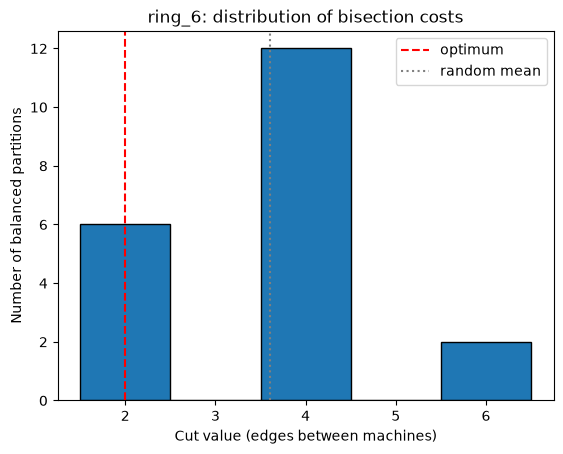

In [ ]:
# draw the graphic for a chosen instance
instance = find_instance(instances, "ring_6")
graph = json_to_graph(instance)

costs = bisection_all_costs(graph)
optimum, _ = bisection_bruteforce(graph)
mean = np.mean(costs)

# one bar for every integer cost
bins = range(min(costs), max(costs) + 2)
plt.hist(costs, bins=bins, align="left", edgecolor="black")

# reference lines
plt.axvline(optimum, color="red", linestyle="--", label="optimum")
plt.axvline(mean, color="gray", linestyle=":", label="random mean")

# labels
plt.xlabel("Cut value (edges between machines)")
plt.ylabel("Number of balanced partitions")
plt.title(instance["name"] + ": distribution of bisection costs")
plt.legend()

plt.savefig("../figures/S_costs_" + instance["name"] + ".png", dpi=150)
plt.show()

**Interpretation:** ring_6 has 20 balanced partitions: 6 are optimal (cut 2), 12 cut 4 edges and 2 cut 6

Random guessing therefore finds the optimum 30% of the time and has an average cut of 3.6 - these two lines
are the reference points of the score S used later (S = 0 at the random mean, S = 1 at the optimum)

On small graphs the optimum is easy to hit by chance; as n grows, the optimal partitions become a tiny fraction of all
balanced partitions, which is why the improvement factor over random guessing (F3) is the more telling metric at n = 14